<p style="text-align: center; font-size: 32px; font-weight: bold;"><u>Vortex Panel Method</u></p>
<h3 align="left">Anchal Bhupal</h3>
<h3 align="left">SC26M006</h3>
<p align="left">AE 611 &ndash; Assignment on the 2D Vortex Panel Method</p>

# 1. Vortex Panel Methods
## 1.1 Aim:
This assignment aims to implement and study two-dimensional vortex panel methods for predicting the aerodynamic characteristics of a circular cylinder and airfoils.
The main objectives are: \
1. To develop algorithms for the constant-strength and linear-strength vortex panel methods.
2. To implement the algorithms in Python as `vortex_panel_method_0()` and `vortex_panel_method_1()`.
3. To verify the implementations against the exact pressure distribution around a circular cylinder and study convergence.
4. To verify them on a symmetric (NACA0012) and a cambered (NACA4412) airfoil, and to investigate convergence with the number of panels and with the distribution of panel lengths.
5. To predict the aerodynamic characteristics ($C_l$) and the pressure-coefficient distributions of one symmetric and one cambered airfoil.
6. To show how increasing airfoil thickness reduces the predictive capability of the method, and so identify the limitations of panel methods.

The study helps clarify how surface discretisation affects the numerical solution, how the choice of vortex-strength representation influences it, and where the inviscid model stops being a reliable predictor.

## 1.2 Introduction to Vortex Panel Method
A panel method estimates the flow around a body by representing its surface as a collection of small straight-line segments called panels. Instead of solving the flow equations at every point in the fluid domain, the flow is represented by mathematical singularities (sources, doublets, or vortices) distributed along the body surface, so only the surface needs to be discretised _(Katz and Plotkin, 2001)_. In a vortex panel method, each panel carries a vortex distribution. Its strength is found by applying the boundary conditions on the body surface; once the strengths are known, the velocity and pressure coefficient on the surface.\
The vortex strengths follow from the no-penetration condition, which makes the surface a streamline by setting the normal velocity to zero at each panel midpoint (control point), and from the Kutta condition, which makes the flow leave a sharp trailing edge smoothly.
Two types are considered:\
- **Constant-strength vortex panels** (first-order representation): the strength is constant along each panel.
- **Linear-strength vortex panels** (second-order representation): the strength varies linearly along each panel and is continuous from panel to panel.

Both are based on the assumption of steady, two-dimensional, incompressible, inviscid and irrotational flow, so the velocity potential satisfies Laplace's equation and superposition applies. They are useful for pressure distributions and lift in attached flow, but they do not model viscous effects such as boundary-layer growth and separation.

**Conventions used throughout** (same as Liu, 2018, and Kuethe & Chow, 1998):
- Boundary points $(x_1,y_1),\dots,(x_{N+1},y_{N+1})$ are ordered **clockwise, starting at the trailing edge**, so panel $j$ joins node $j$ to node $j+1$ and $N$ panels are obtained. For an airfoil, the order is lower surface (TE $\to$ LE), then upper surface (LE $\to$ TE).
- $\theta_j$ is the angle of panel $j$ from the $x$-axis. The panel unit tangent is $\mathbf t_j=(\cos\theta_j,\sin\theta_j)$ and the outward normal is $\mathbf n_j=(-\sin\theta_j,\cos\theta_j)$.
- $\gamma>0$ is a **clockwise** vortex sheet, so that a positive $\gamma$ on the upper surface speeds up the flow (positive lift).
- Free stream: $V_\infty(\cos\alpha,\sin\alpha)$.

## 1.3 Local influence of one panel
Let $(\xi,\eta)$ be coordinates of control point $i$ in the frame of panel $j$ (origin at node $j$, $\xi$ along the panel, $\eta$ along $\mathbf n_j$, $S_j$ = panel length). With
$$\phi_1=\operatorname{atan2}(\eta,\xi),\quad \phi_2=\operatorname{atan2}(\eta,\xi-S_j),\quad r_1=\sqrt{\xi^2+\eta^2},\quad r_2=\sqrt{(\xi-S_j)^2+\eta^2},$$
$$\Delta\phi=\phi_2-\phi_1,\qquad L=\ln\frac{r_2}{r_1},$$
a vortex sheet $\gamma(\xi')$ on $0\le\xi'\le S_j$ induces the local velocity components
$$u_\xi=\frac{1}{2\pi}\int_0^{S_j}\frac{\gamma\,\eta\,d\xi'}{(\xi-\xi')^2+\eta^2},\qquad u_\eta=-\frac{1}{2\pi}\int_0^{S_j}\frac{\gamma\,(\xi-\xi')\,d\xi'}{(\xi-\xi')^2+\eta^2}.$$
These are rotated into the normal and tangent of panel $i$:
$$u_n = u_\xi\sin(\theta_j-\theta_i)+u_\eta\cos(\theta_j-\theta_i),\qquad u_t = u_\xi\cos(\theta_j-\theta_i)-u_\eta\sin(\theta_j-\theta_i).$$
For $i=j$ the control point lies on the sheet: $\xi=S_j/2$, $\eta\to0^+$ (outer side), hence $\Delta\phi=\pi$ and $L=0$. This is what produces the familiar $\gamma/2$ jump in the tangential velocity.

## 1.4 Constant-strength vortex panels (`vortex_panel_method_0()`)
The surface is divided into $N$ panels and a single unknown strength $\gamma_j$ is assigned to each panel. The velocity at a control point is the sum of the free-stream velocity and the velocities induced by all panels. The no-penetration condition $\mathbf V_i\cdot\mathbf n_i=0$ at all control points, together with the closure condition (Kutta condition for a sharp trailing edge), gives a linear system $\mathbf A\boldsymbol\gamma=\mathbf b$, where $\mathbf A$ holds the vortex influence coefficients and $\mathbf b$ the free-stream contribution (Anderson; Katz & Plotkin, 2001).

Unknowns: $\gamma_1,\dots,\gamma_N$ (one per panel, $\gamma(s)=\gamma_j$).

For constant $\gamma_j$: $u_\xi=\gamma_j\Delta\phi/2\pi$, $u_\eta=\gamma_j L/2\pi$. Therefore the influence coefficients are
$$A_{ij}=\frac{1}{2\pi}\Big[\Delta\phi_{ij}\sin(\theta_j-\theta_i)+L_{ij}\cos(\theta_j-\theta_i)\Big]\ (\text{normal}),\qquad T_{ij}=\frac{1}{2\pi}\Big[\Delta\phi_{ij}\cos(\theta_j-\theta_i)-L_{ij}\sin(\theta_j-\theta_i)\Big]\ (\text{tangential}).$$

1. Generate the boundary points (clockwise, from the trailing edge); choose the panel distribution.
2. Compute for every panel: length $S_j$, angle $\theta_j$, control point (mid-point).
3. For every pair $(i,j)$ compute $\xi,\eta,\Delta\phi,L$ in the frame of panel $j$ (self-term: $\Delta\phi=\pi$, $L=0$).
4. Assemble the normal-velocity matrix $A_{ij}$ and tangential matrix $T_{ij}$.
5. No-penetration at every control point: $\sum_j A_{ij}\gamma_j = V_\infty\sin(\theta_i-\alpha)$, $i=1..N$.
6. Closure equation:
   - sharp trailing edge: Kutta condition $\gamma_1+\gamma_N=0$;
   - smooth closed body (cylinder): zero net circulation $\sum_j\gamma_jS_j=0$.
7. The $(N+1)\times N$ system is solved in the least-squares sense with a truncated SVD (an SVD-based solve is used so that the solution stays free of odd/even oscillations).
8. Tangential velocity at control points: $V_{t,i}=V_\infty\cos(\theta_i-\alpha)+\sum_jT_{ij}\gamma_j$.
9. Pressure coefficient $C_{p,i}=1-(V_{t,i}/V_\infty)^2$.
10. Lift coefficient from the Kutta-Joukowski theorem, $C_l=2\sum_j\gamma_jS_j/(V_\infty c)$.

## 1.5 Linear-strength vortex panels (`vortex_panel_method_1()`)
Here the strength varies linearly over each panel between its two end points. This can follow variations of the circulation more smoothly than a piecewise-constant distribution, but the accuracy still depends on the formulation, the boundary conditions and the panel distribution. The end-point strengths of neighbouring panels are shared, so that $\gamma$ is continuous along the surface, and the influence integrals must account for the linear variation (_Kuethe & Chow, 1998; Liu, 2018_).

Unknowns: nodal strengths $\gamma_1,\dots,\gamma_{N+1}$, with $\gamma$ varying linearly on each panel and **continuous** across nodes:
$$\gamma(s)=\gamma_j+(\gamma_{j+1}-\gamma_j)\frac{s}{S_j},\qquad 0\le s\le S_j.$$
Using $J_1=\Delta\phi$, $J_2=-L$, $K_1=\xi\Delta\phi+\eta L$, $K_2=-\xi L-S_j+\eta\Delta\phi$ the local velocities per unit nodal strength are
$$u_\xi^{(a)}=\frac{J_1-K_1/S_j}{2\pi},\ u_\xi^{(b)}=\frac{K_1/S_j}{2\pi},\qquad u_\eta^{(a)}=-\frac{J_2-K_2/S_j}{2\pi},\ u_\eta^{(b)}=-\frac{K_2/S_j}{2\pi},$$
where $(a)$ multiplies $\gamma_j$ and $(b)$ multiplies $\gamma_{j+1}$. These give two $N\times N$ coefficient sets which are rotated exactly as above; they are equivalent to $C_{n1},C_{n2},C_{t1},C_{t2}$ of Liu (2018), Eqs. (11)&ndash;(21).

1. Generate boundary points and panel geometry as in the constant-strength vortex panel algorithm.
2. For every $(i,j)$ compute the $(a)$ and $(b)$ coefficients; the self-term uses $\xi=S_j/2,\ \eta=0^+$.
3. Assemble $A_{i,j}\mathrel{+}=A^{(a)}_{ij}$ and $A_{i,j+1}\mathrel{+}=A^{(b)}_{ij}$ (each node strength gets contributions from the two panels that share it), giving an $N\times(N+1)$ matrix. Same for the tangential matrix $T$.
4. No-penetration at all $N$ control points: $\sum_{j=1}^{N+1}A_{ij}\gamma_j=V_\infty\sin(\theta_i-\alpha)$.
5. Closure: Kutta condition $\gamma_1+\gamma_{N+1}=0$ (airfoil), or for the cylinder $\gamma_1=\gamma_{N+1}$ plus zero net circulation.
6. Solve the resulting system for the $N+1$ nodal strengths.
7. $V_{t,i}=V_\infty\cos(\theta_i-\alpha)+\sum_jT_{ij}\gamma_j$, $\;C_{p,i}=1-(V_{t,i}/V_\infty)^2$.
8. $C_l = \dfrac{2}{V_\infty c}\sum_j S_j\dfrac{\gamma_j+\gamma_{j+1}}{2}$ (exact integral of the linear sheet).
9. Repeat for different $N$ and panel distributions for the convergence studies.

The linear method is not obtained by interpolating the constant-strength solution: the integrals of the linearly varying sheet are evaluated exactly, as in _Liu (2018)_.

# 2. Python Implementation
## 2.1 Generation of geometry
- `cylinder_geometry(N, R)` returns $N+1$ points on a circle, clockwise from $(R,0)$.
- `naca_geometry(code, N, spacing)` returns $N+1$ points of a NACA 4-digit airfoil (chord$=1$), ordered as : TE $\to$ lower $\to$ LE $\to$ upper $\to$ TE.
  With `spacing` = `'cosine'` or `'uniform'`, the points are placed along the chord at $x=\tfrac{1}{2}(1-\cos\pi s)$ or $x=s$ respectively, with $s\in[0,1]$ uniformly spaced.

The thickness distribution is: \
 $$y_t=5t\,(0.2969\sqrt{x}-0.1260x-0.3516x^2+0.2843x^3-0.1036x^4)$$
 The last coefficient is $-0.1036$ (not $-0.1015$ as in Liu's paper), so that the trailing edge is exactly **closed**; with $-0.1015$, the trailing edge is open (a gap of about 0.25 % of the chord for $t=12\%$) and the Kutta condition between the first and last panels would be ill-posed. The geometry follows _Abbott & von Doenhoff (1959)_. The camber line and the rotation of the thickness by the local camber-line angle follow the standard NACA formulas.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (8, 5), "font.size": 11, "axes.grid": True, "grid.alpha": 0.3})

In [3]:
def cylinder_geometry(N, R=1.0):
    # N+1 boundary points on a circle of radius R, clockwise, starting at (R, 0)
    th = np.linspace(0.0, 2*np.pi, N + 1)
    return R*np.cos(th), -R*np.sin(th)


def naca4_geometry(code, N, spacing="cosine"):
    # N+1 boundary points (N even) of a NACA 4-digit airfoil, chord = 1
    # Order: TE -> lower surface -> LE -> upper surface -> TE (clockwise)
    # spacing = 'cosine' or 'uniform' (chordwise station distribution)
    m, p, t = int(code[0])/100, int(code[1])/10, int(code[2:])/100
    h = N//2
    s = np.linspace(0.0, 1.0, h + 1)
    x = 0.5*(1 - np.cos(np.pi*s)) if spacing == "cosine" else s
    yt = 5*t*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1036*x**4)
    if m == 0 or p == 0:
        yc, dyc = np.zeros_like(x), np.zeros_like(x)
    else:
        yc  = np.where(x < p, m/p**2*(2*p*x - x**2), m/(1-p)**2*((1 - 2*p) + 2*p*x - x**2))
        dyc = np.where(x < p, 2*m/p**2*(p - x),      2*m/(1-p)**2*(p - x))
    th = np.arctan(dyc)
    xu, yu = x - yt*np.sin(th), yc + yt*np.cos(th)
    xl, yl = x + yt*np.sin(th), yc - yt*np.cos(th)
    xb = np.concatenate([xl[::-1], xu[1:]])
    yb = np.concatenate([yl[::-1], yu[1:]])
    xb[0] = xb[-1] = 1.0; yb[0] = yb[-1] = 0.0      # closed trailing edge
    return xb, yb


def panel_geometry(xb, yb):
    # Mid-points (control points), lengths and angles of the panels
    dx, dy = np.diff(xb), np.diff(yb)
    return {"xc": 0.5*(xb[:-1] + xb[1:]), "yc": 0.5*(yb[:-1] + yb[1:]),
            "S": np.hypot(dx, dy), "theta": np.arctan2(dy, dx)}

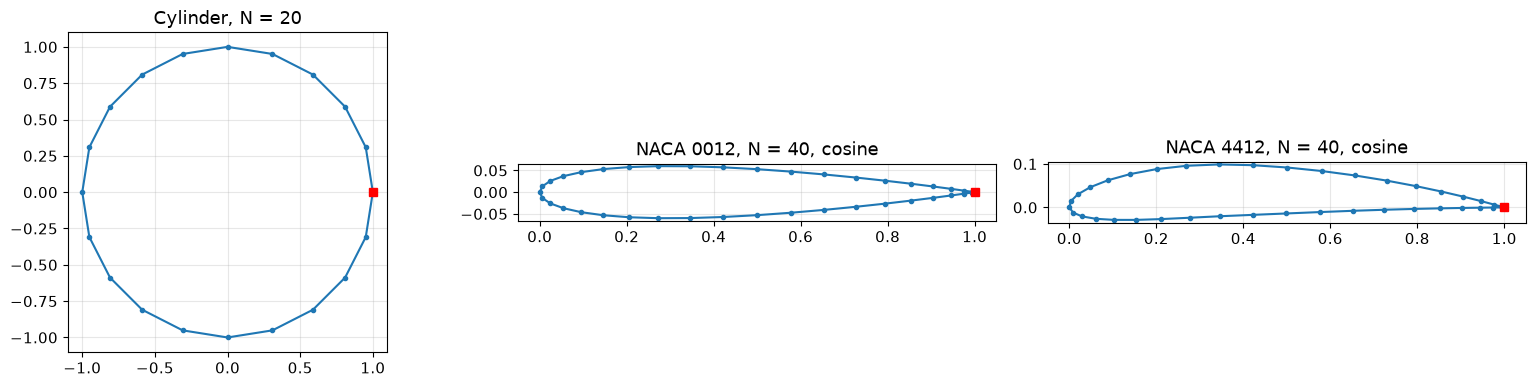

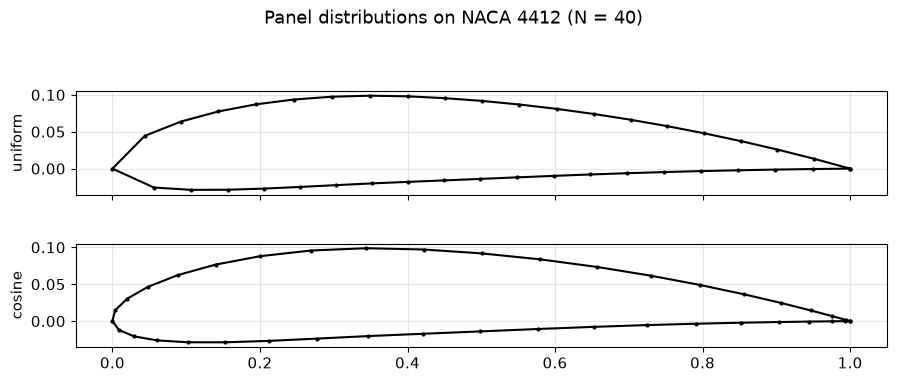

In [4]:
#plotting geometries
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (name, (xb, yb)) in zip(ax, {
        "Cylinder, N = 20": cylinder_geometry(20),
        "NACA 0012, N = 40, cosine": naca4_geometry("0012", 40),
        "NACA 4412, N = 40, cosine": naca4_geometry("4412", 40)}.items()):
    a.plot(xb, yb, "o-", ms=3); a.plot(xb[0], yb[0], "rs"); a.set_aspect("equal"); a.set_title(name)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
for a, sp in zip(ax, ["uniform", "cosine"]):
    xb, yb = naca4_geometry("4412", 40, sp)
    a.plot(xb, yb, "k.-", ms=4); a.set_aspect("equal"); a.set_ylabel(sp)
plt.suptitle("Panel distributions on NACA 4412 (N = 40)"); plt.tight_layout(); plt.show()

# 2.2 Coefficients that influence and two solvers
The function `influence()` evaluates (vectorised over all pairs ($i,j$)) the local geometries and returns the normal and tangential coefficient matrices for the constant panels (`Nc`, `Tc`) and for the linear panels (`Na`, `Nb`, `Ta`, `Tb`).

| Argument / output | Meaning |
|---|---|
| `xb, yb` | $N+1$ boundary points, clockwise, starting at the trailing edge |
| `alpha_deg` | angle of attack in degrees |
| `V_inf` | free-stream speed (default 1) |
| `kutta` | `True`: Kutta condition (airfoil). `False`: zero net circulation (cylinder) |
| `rcond` | relative singular-value cut-off of the least-squares solve |
| returns `gamma` | vortex strengths (N for method 0, N+1 nodal values for method 1) |
| returns `Vt`, `Cp` | tangential velocity and pressure coefficient at the control points |
| returns `Cl` | lift coefficient from circulation (Kutta-Joukowski) |
| returns `xc, yc, S, theta` | panel control points, lengths and angles |

The panel distribution (uniform or cosine) is chosen when the boundary points are generated, through the `spacing` argument of `naca4_geometry()` and `cylinder_geometry()`; the solvers work on any set of boundary points.

The pressure coefficient is obtained from the local tangential velocity with Bernoulli's equation:
$$C_p=\frac{p-p_\infty}{\tfrac12\rho V_\infty^2}=1-\Big(\frac{V_t}{V_\infty}\Big)^2,$$
where $p_\infty$ and $V_\infty$ are the free-stream static pressure and speed ($V_\infty$ is written as $U_\infty$).

In [5]:
def influence(xb, yb):
    # Normal (N) and tangential (T) influence matrices of constant and linear vortex panels
    # Constant strength: Nc, Tc   (N x N)
    # Linear strength: Na, Ta multiply gamma_j ; Nb, Tb multiply gamma_{j+1}   (N x N each)
    g = panel_geometry(xb, yb)
    xc, yc, S, th = g["xc"], g["yc"], g["S"], g["theta"]
    N = len(S)
    dx = xc[:, None] - xb[None, :-1] # control point i relative to start of panel j
    dy = yc[:, None] - yb[None, :-1]
    c, s = np.cos(th)[None, :], np.sin(th)[None, :]
    xi  =  dx*c + dy*s # coordinates in the frame of panel j
    eta = -dx*s + dy*c
    Sj = S[None, :]
    phi1, phi2 = np.arctan2(eta, xi), np.arctan2(eta, xi - Sj)
    r1, r2 = np.hypot(xi, eta), np.hypot(xi - Sj, eta)
    d = np.arange(N)
    xi[d, d], eta[d, d] = S/2, 0.0 # self-influence: on the sheet, outer side
    with np.errstate(divide="ignore", invalid="ignore"):
        dphi, L = phi2 - phi1, np.log(r2/r1)
    dphi[d, d], L[d, d] = np.pi, 0.0
    J1, J2 = dphi, -L
    K1 = xi*dphi + eta*L
    K2 = -xi*L - Sj + eta*dphi
    dth = th[None, :] - th[:, None] # theta_j - theta_i
    sn, cs = np.sin(dth), np.cos(dth)
    rot = lambda ux, ue: (ux*sn + ue*cs, ux*cs - ue*sn) # (normal, tangential) of panel i
    Nc, Tc = rot(dphi/(2*np.pi), L/(2*np.pi))
    Na, Ta = rot((J1 - K1/Sj)/(2*np.pi), -(J2 - K2/Sj)/(2*np.pi))
    Nb, Tb = rot((K1/Sj)/(2*np.pi),      -(K2/Sj)/(2*np.pi))
    return g, {"Nc": Nc, "Tc": Tc, "Na": Na, "Nb": Nb, "Ta": Ta, "Tb": Tb}


def _solve(A, b, rcond):
    U, s, Vh = np.linalg.svd(A, full_matrices=False)
    keep = s > rcond*s[0]
    return Vh[keep].T @ ((U[:, keep].T @ b)/s[keep])

In [6]:
def vortex_panel_method_0(xb, yb, alpha_deg, V_inf=1.0, kutta=True, rcond=1e-3):
    # Constant-strength vortex panel method
    # Returns gamma (N), Vt, Cp, Cl and the panel data xc, yc, S, theta
    a = np.radians(alpha_deg)
    g, I = influence(xb, yb)
    th, S = g["theta"], g["S"]
    N = len(S)
    closure = np.zeros(N)
    if kutta:
        closure[0] = closure[-1] = 1.0 # gamma_1 + gamma_N = 0
    else:
        closure = S.copy() # sum(gamma_j S_j) = 0
    A = np.vstack([I["Nc"], closure])
    b = np.append(V_inf*np.sin(th - a), 0.0)
    gamma = _solve(A, b, rcond)
    Vt = V_inf*np.cos(th - a) + I["Tc"] @ gamma # tangential velocity at control points
    Cp = 1 - (Vt/V_inf)**2
    Cl = 2*np.sum(gamma*S)/(V_inf*(xb.max() - xb.min())) # Kutta-Joukowski
    return {"gamma": gamma, "Vt": Vt, "Cp": Cp, "Cl": Cl,
            "xc": g["xc"], "yc": g["yc"], "S": S, "theta": th}


def vortex_panel_method_1(xb, yb, alpha_deg, V_inf=1.0, kutta=True, rcond=1e-10):
    # Linear-strength vortex panel method
    # Returns a dictionary with gamma (N+1), Vt, Cp, Cl and the panel data xc, yc, S, theta
    a = np.radians(alpha_deg)
    g, I = influence(xb, yb)
    th, S = g["theta"], g["S"]
    N = len(S)
    A = np.zeros((N, N + 1)); T = np.zeros((N, N + 1))
    A[:, :N] += I["Na"]; A[:, 1:] += I["Nb"] # node j gets contributions of panels j-1 and j
    T[:, :N] += I["Ta"]; T[:, 1:] += I["Tb"]
    b = V_inf*np.sin(th - a)
    if kutta:
        k = np.zeros(N + 1); k[0] = k[N] = 1.0 # gamma_1 + gamma_{N+1} = 0
        A, b = np.vstack([A, k]), np.append(b, 0.0)
    else: # closed smooth body
        r1 = np.zeros(N + 1); r1[0], r1[N] = 1.0, -1.0 # gamma_1 = gamma_{N+1}
        r2 = np.zeros(N + 1); r2[:N] += S/2; r2[1:] += S/2 # zero net circulation
        A, b = np.vstack([A, r1, r2]), np.append(b, [0.0, 0.0])
    gamma = _solve(A, b, rcond)
    Vt = V_inf*np.cos(th - a) + T @ gamma
    Cp = 1 - (Vt/V_inf)**2
    Cl = 2*np.sum(S*0.5*(gamma[:-1] + gamma[1:]))/(V_inf*(xb.max() - xb.min()))
    return {"gamma": gamma, "Vt": Vt, "Cp": Cp, "Cl": Cl,
            "xc": g["xc"], "yc": g["yc"], "S": S, "theta": th}

# 3. Verification for circular cylinder
## 3.1 Analytical solution
For a cylinder without circulation, the speed over the surface is given by: $V_\theta=-2V_\infty\sin\theta$ and
$$C_p = 1-4\sin^2\theta,\qquad C_l=0 .$$
A cylinder has no sharp trailing edge, so no Kutta condition is applied (`kutta=False`); instead, the net circulation is set to zero. Panels are generated by `cylinder_geometry()`. The error is measured at the control points against the exact $C_p$ at the polar angle of each control point:
$$E_{max}=\max_i|C_{p,i}-C_{p,i}^{exact}|,\qquad E_{RMS}=\sqrt{\tfrac1N\sum_i (C_{p,i}-C_{p,i}^{exact})^2}.$$
The observed order of convergence between $N$ and $2N$ is $p=\log_2(E_N/E_{2N})$.

The angle $\theta$ is measured around the cylinder from the stagnation points on the $x$-axis ($C_p$ depends only on $\sin^2\theta$). The cylinder is discretised with $N=10$ to $80$ and up to $320$ straight panels, and both methods are run with the same geometry.

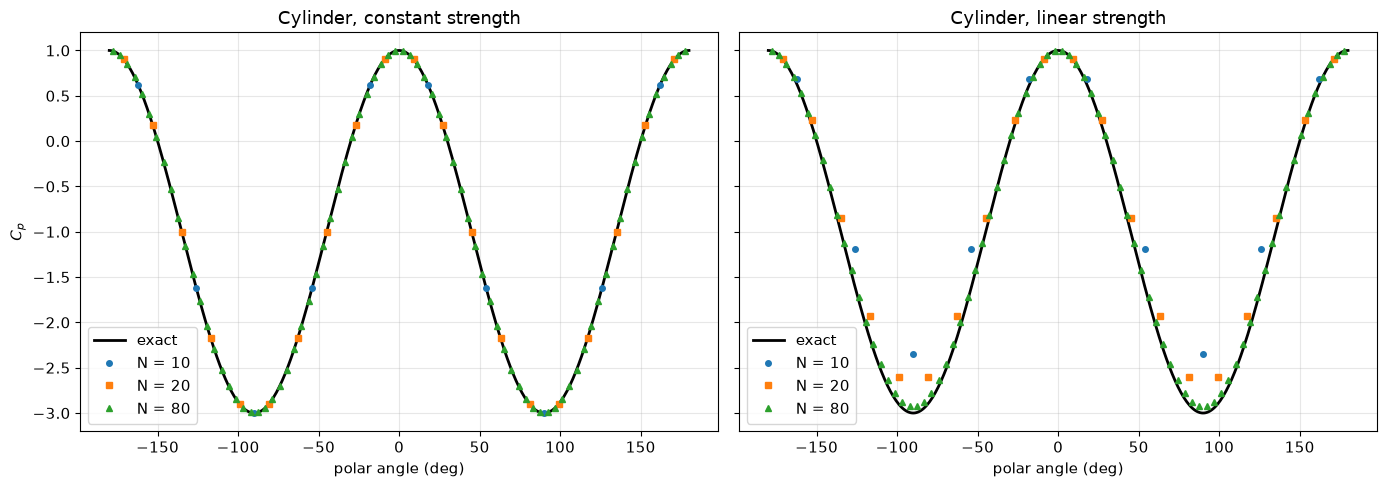

In [7]:
def cyl_error(method, N):
    # Max and RMS Cp error (against Cp = 1 - 4 sin^2(theta)) at the control points of an N-panel cylinder
    xb, yb = cylinder_geometry(N)
    r = method(xb, yb, 0.0, kutta=False)
    phi = np.arctan2(r["yc"], r["xc"])
    err = r["Cp"] - (1 - 4*np.sin(phi)**2)
    return np.abs(err).max(), np.sqrt(np.mean(err**2)), r, phi

# Cp distributions for a few N
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
pe = np.linspace(-np.pi, np.pi, 400)
for a, (method, name) in zip(ax, [(vortex_panel_method_0, "constant strength"), (vortex_panel_method_1, "linear strength")]):
    a.plot(np.degrees(pe), 1 - 4*np.sin(pe)**2, "k", lw=2, label="exact")
    for N, mk in [(10, "o"), (20, "s"), (80, "^")]:
        _, _, r, phi = cyl_error(method, N)
        a.plot(np.degrees(phi), r["Cp"], mk, ms=4, label=f"N = {N}")
    a.set_title(f"Cylinder, {name}"); a.set_xlabel("polar angle (deg)"); a.legend(); a.invert_yaxis()
ax[0].set_ylabel("$C_p$"); plt.tight_layout(); plt.show()

    N |        method 0 (constant)         |         method 1 (linear)         
   10 | Emax= 4.44e-15  Erms= 1.78e-15 | Emax= 6.52e-01  Erms= 4.00e-01
   20 | Emax= 1.02e-14  Erms= 4.39e-15 | Emax= 2.96e-01  Erms= 1.86e-01
   40 | Emax= 1.73e-14  Erms= 6.78e-15 | Emax= 1.45e-01  Erms= 8.91e-02
   80 | Emax= 4.93e-14  Erms= 1.63e-14 | Emax= 7.09e-02  Erms= 4.35e-02
  160 | Emax= 1.38e-13  Erms= 4.82e-14 | Emax= 3.51e-02  Erms= 2.15e-02
  320 | Emax= 1.97e-13  Erms= 6.81e-14 | Emax= 1.74e-02  Erms= 1.07e-02


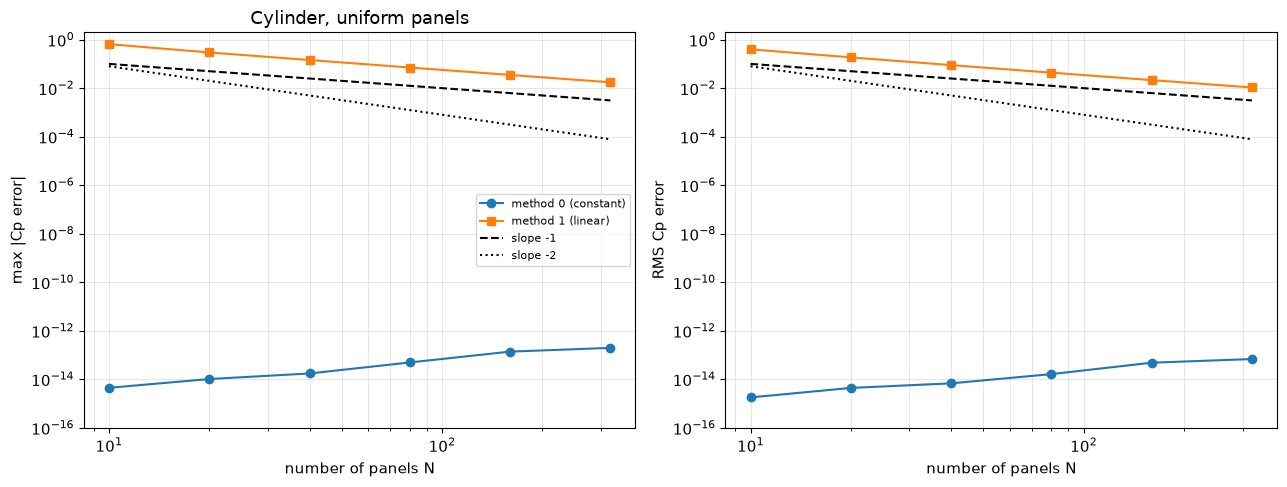

Observed order of convergence (RMS error), method 1: [np.float64(1.1), np.float64(1.06), np.float64(1.03), np.float64(1.02), np.float64(1.01)]
Max |Cl| on the cylinder (should be 0): 2.4733687320477316e-14


In [8]:
Ns = [10, 20, 40, 80, 160, 320]
cases = {"method 0 (constant)": vortex_panel_method_0, "method 1 (linear)": vortex_panel_method_1}
res = {k: [] for k in cases}
for k, m in cases.items():
    for N in Ns:
        emax, erms, r, _ = cyl_error(m, N)
        res[k].append((emax, erms, abs(r["Cl"])))

print(f"{'N':>5s} | " + " | ".join(f"{k:^34s}" for k in cases))
for n, N in enumerate(Ns):
    print(f"{N:5d} | " + " | ".join(f"Emax={res[k][n][0]:9.2e}  Erms={res[k][n][1]:9.2e}" for k in cases))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k, mk in zip(cases, ["o-", "s-"]):
    ax[0].loglog(Ns, [e[0] for e in res[k]], mk, label=k)
    ax[1].loglog(Ns, [e[1] for e in res[k]], mk, label=k)
Na_ = np.array(Ns, float)
for a in ax:
    a.loglog(Ns, 1/Na_, "k--", label="slope -1"); a.loglog(Ns, 8/Na_**2, "k:", label="slope -2")
    a.set_xlabel("number of panels N"); a.grid(True, which="both"); a.set_ylim(1e-16, 2)
ax[0].set_ylabel("max |Cp error|"); ax[1].set_ylabel("RMS Cp error"); ax[0].legend(fontsize=8)
ax[0].set_title("Cylinder, uniform panels"); plt.tight_layout(); plt.show()

print("Observed order of convergence (RMS error), method 1:",
      [round(np.log2(res["method 1 (linear)"][i-1][1]/res["method 1 (linear)"][i][1]), 2) for i in range(1, len(Ns))])
print("Max |Cl| on the cylinder (should be 0):", max(e[2] for k in res for e in res[k]))

## 3.2 Result discussion for circular cylinder
- Both methods reproduce the exact pressure distribution; the computed lift is zero to round-off, and the errors do not grow with $N$: the implementations are consistent.
- With uniform panels, the constant-strength method is accurate to round-off at every $N$.
- The linear method converges at about first order on the cylinder (the RMS error halves each time $N$ doubles, observed order close to 1) and its error is larger than that of the constant method on this particular test. A formally higher-order representation of the strength therefore does not automatically give a smaller surface-pressure error; the quantity that is compared matters.
- The pressure coefficient is the quantity most sensitive to the discretisation.

# 4. Verification for airfoils
For the symmetric airfoil case, we are analysing the NACA 0012, which has $t/c = 12\%$, and for the cambered case, we are analysing the NACA 4412, which has $m = 4\%$, $p=40\%$, $t=12\%$.

**Set-up**: The airfoil coordinates are generated using the standard NACA four-digit equations and discretised into straight panels, ordered clockwise from the trailing edge so that the panel orientation is consistent with the Kutta condition. Both methods use the same free-stream conditions and panels, which makes it easier to compare the airfoil results.

From the _Liu(2018)_ paper, the linear-strength method is discretised with $N=1280$ using the cosine-spaced panels. As an independent check, _Liu(2018)_, _Fig. 3_, reports $C_l\approx1.467$ for the NACA 4412 at $\alpha=8^\circ$ with 160 panels (Xfoil and his linear vortex panels); the converged value computed here is about 1.476, a difference of about 0.6 %. (Liu obtains $C_l$ by integrating the surface pressure, whereas here it is computed from the circulation, so a small difference is expected.)

In [11]:
ALPHA = {"0012":5.0, "4412":8.0}
ref={}
for code_ in ["0012","4412"]:
    r=vortex_panel_method_1(*naca4_geometry(code_,1280,"cosine"), ALPHA[code_])
    ref[code_]=r
    print(f"NACA {code_}, alpha = {ALPHA[code_]} deg, reference (N = 1280, cosine): Cl = {r['Cl']:.5f}, Cp_min = {r['Cp'].min():.3f}")

NACA 0012, alpha = 5.0 deg, reference (N = 1280, cosine): Cl = 0.60301, Cp_min = -2.054
NACA 4412, alpha = 8.0 deg, reference (N = 1280, cosine): Cl = 1.47593, Cp_min = -3.711


## 4.1 Cosine spacing on panels
The lift and pressure coefficients --- $Cl$ (using the circulation) and $C_{p, min}$ (reading the suction-peak value) are monitored on the upper surface, and the relative error is taken against the reference. The upper-surface pressure distributions are also compared for increasing $N$.

airfoil method       N       Cl    Cpmin   |dCl|%  |dCpmin|%
0012    const       10   0.6166   -1.721    2.260     16.218
0012    const       20   0.6180   -1.995    2.483      2.860
0012    const       40   0.6121   -1.988    1.501      3.186
0012    const       80   0.6079   -2.050    0.809      0.183
0012    const      160   0.6055   -2.063    0.419      0.462
0012    const      320   0.6043   -2.062    0.213      0.389
0012    const      640   0.6037   -2.063    0.107      0.468
0012    linear      10   0.5869   -0.795    2.680     61.300
0012    linear      20   0.5982   -1.348    0.804     34.377
0012    linear      40   0.6017   -1.752    0.213     14.706
0012    linear      80   0.6027   -1.901    0.054      7.421
0012    linear     160   0.6029   -1.979    0.013      3.638
0012    linear     320   0.6030   -2.023    0.003      1.501
0012    linear     640   0.6030   -2.044    0.001      0.494
4412    const       10   1.4919   -3.027    1.081     18.445
4412    const       20  

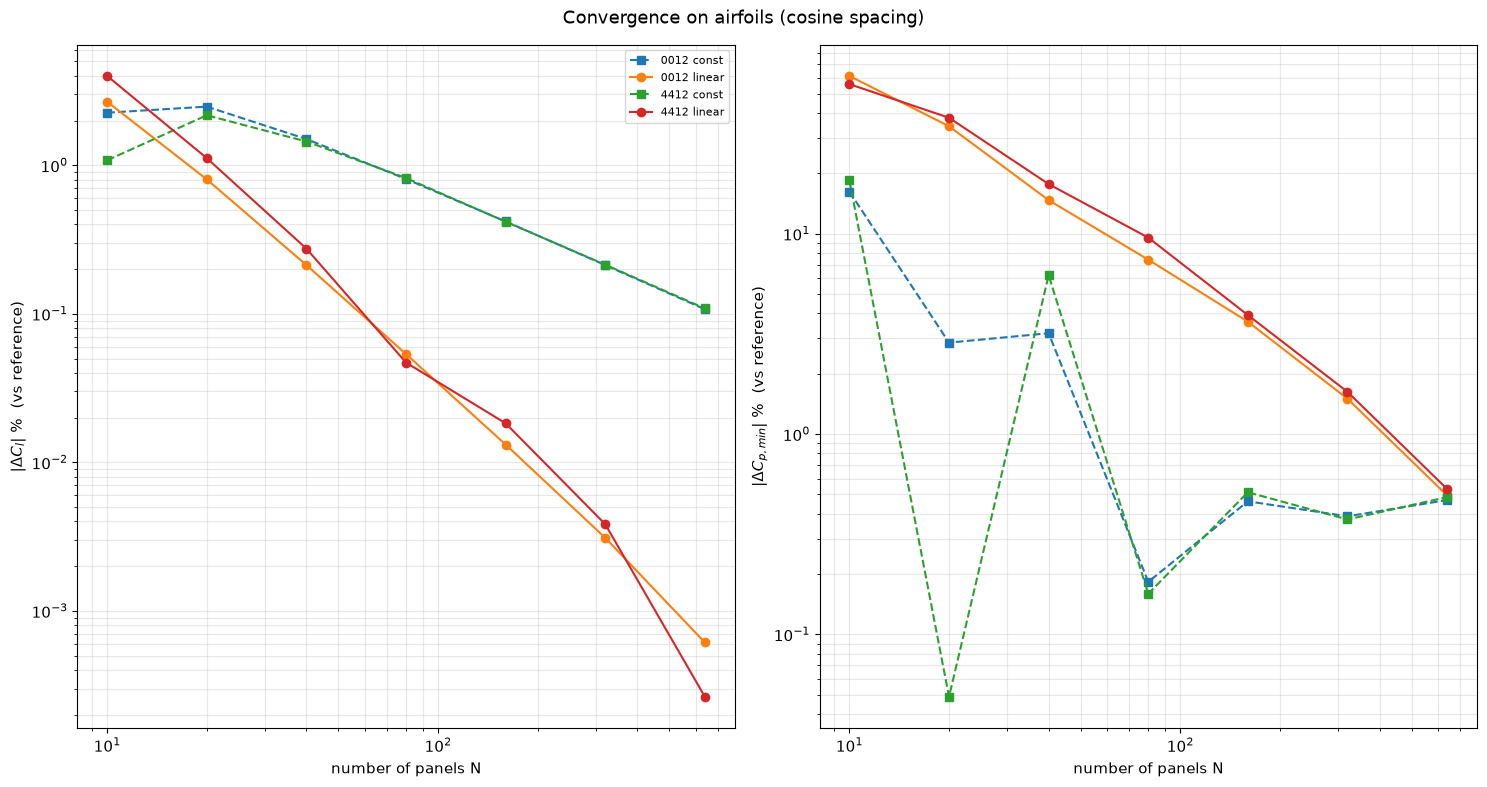

In [12]:
Ns_a = [10, 20, 40, 80, 160, 320, 640]
rows = {}
print(f"{'airfoil':8s}{'method':9s}{'N':>5s}{'Cl':>9s}{'Cpmin':>9s}{'|dCl|%':>9s}{'|dCpmin|%':>11s}")
for code_ in ["0012", "4412"]:
    R = ref[code_]
    for mname, f in [("const", vortex_panel_method_0), ("linear", vortex_panel_method_1)]:
        lst = []
        for N in Ns_a:
            r = f(*naca4_geometry(code_, N, "cosine"), ALPHA[code_])
            e1 = abs(r["Cl"] - R["Cl"])/R["Cl"]*100
            e3 = abs(r["Cp"].min() - R["Cp"].min())/abs(R["Cp"].min())*100
            lst.append((e1, e3))
            print(f"{code_:8s}{mname:9s}{N:5d}{r['Cl']:9.4f}{r['Cp'].min():9.3f}{e1:9.3f}{e3:11.3f}")
        rows[(code_, mname)] = np.array(lst)

fig, ax = plt.subplots(1, 2, figsize=(15, 8))
names = [r"$|\Delta C_l|$ %  (vs reference)", r"$|\Delta C_{p,min}|$ %  (vs reference)"]
for k in range(2):
    for (code_, mname), v in rows.items():
        ax[k].loglog(Ns_a, np.maximum(v[:, k], 1e-5), "o-" if mname == "linear" else "s--", label=f"{code_} {mname}")
    ax[k].set_xlabel("number of panels N"); ax[k].set_ylabel(names[k]); ax[k].grid(True, which="both")
ax[0].legend(fontsize=8); plt.suptitle("Convergence on airfoils (cosine spacing)"); plt.tight_layout(); plt.show()

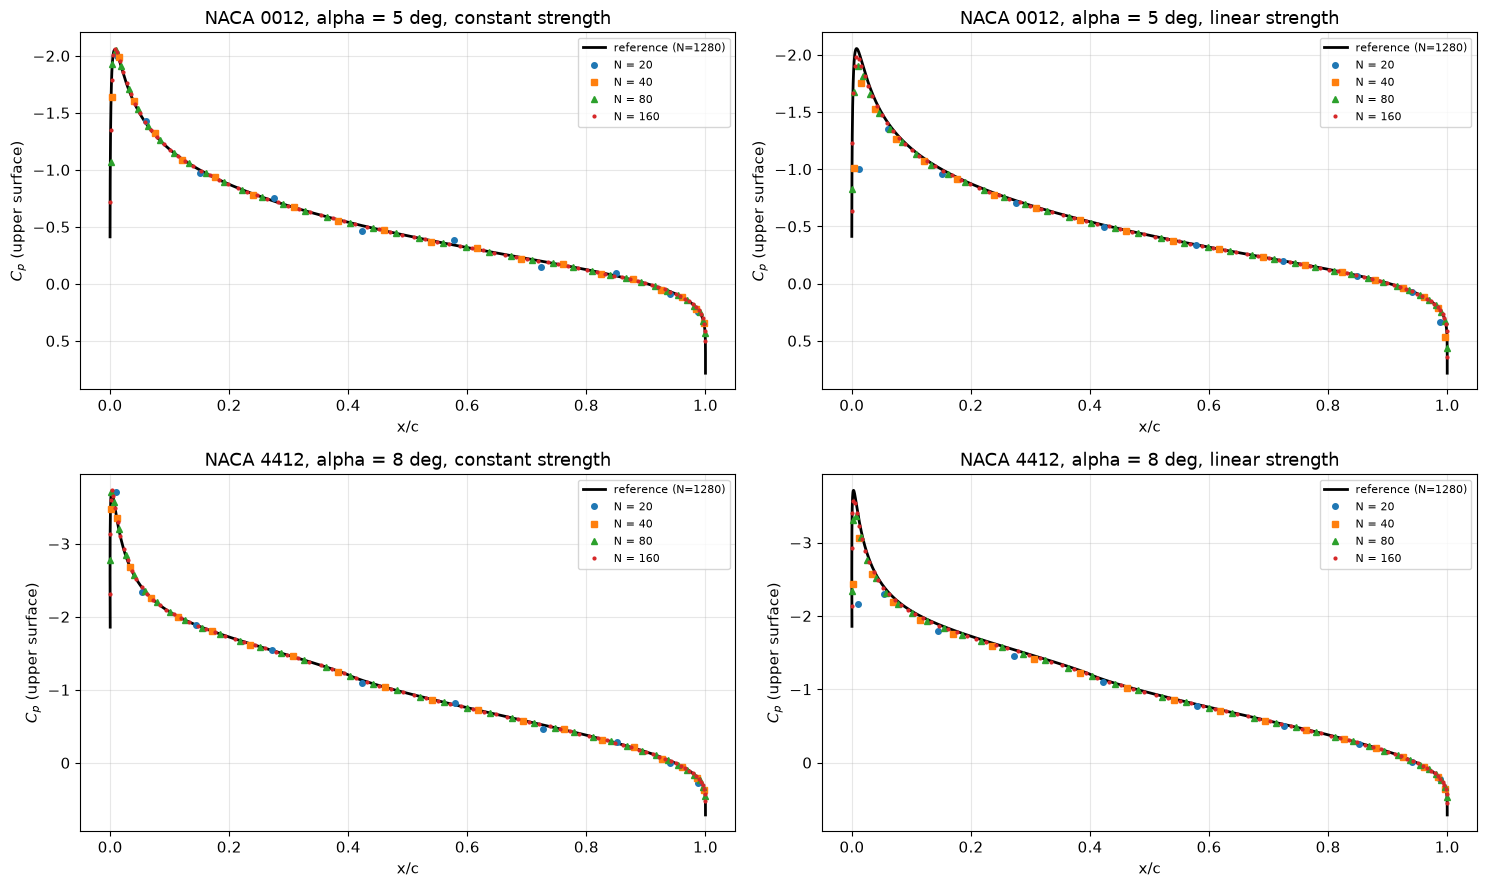

In [13]:
# upper-surface Cp for increasing N (cosine spacing) against the reference 
fig, ax = plt.subplots(2, 2, figsize=(15,9))
for row, code_ in enumerate(["0012", "4412"]):
    R = ref[code_]; hR = len(R["xc"])//2
    for col, (mname, f) in enumerate([("constant strength", vortex_panel_method_0), ("linear strength", vortex_panel_method_1)]):
        A_ = ax[row, col]
        A_.plot(R["xc"][hR:], R["Cp"][hR:], "k-", lw=2, label="reference (N=1280)")
        for N, mk in [(20, "o"), (40, "s"), (80, "^"), (160, ".")]:
            r = f(*naca4_geometry(code_, N, "cosine"), ALPHA[code_])
            A_.plot(r["xc"][N//2:], r["Cp"][N//2:], mk, ms=4, label=f"N = {N}")
        A_.invert_yaxis(); A_.set_title(f"NACA {code_}, alpha = {ALPHA[code_]:.0f} deg, {mname}")
        A_.set_xlabel("x/c"); A_.set_ylabel("$C_p$ (upper surface)"); A_.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4.2 Effect of panel-length distribution
In uniform spacing, the points are equally spaced in x, which is simple but may not give enough resolution where the curvature and the pressure gradients change rapidly. In cosine spacing, $x_i=\tfrac c2\big[1-\cos(i\pi/N_h)\big]$, with $N_h=N/2$ points per surface, the points cluster near the leading and trailing edges. The two distributions are compared at equal $N$ through the lift error against the reference; the pressure distribution at $N=40$ is also compared with the reference.

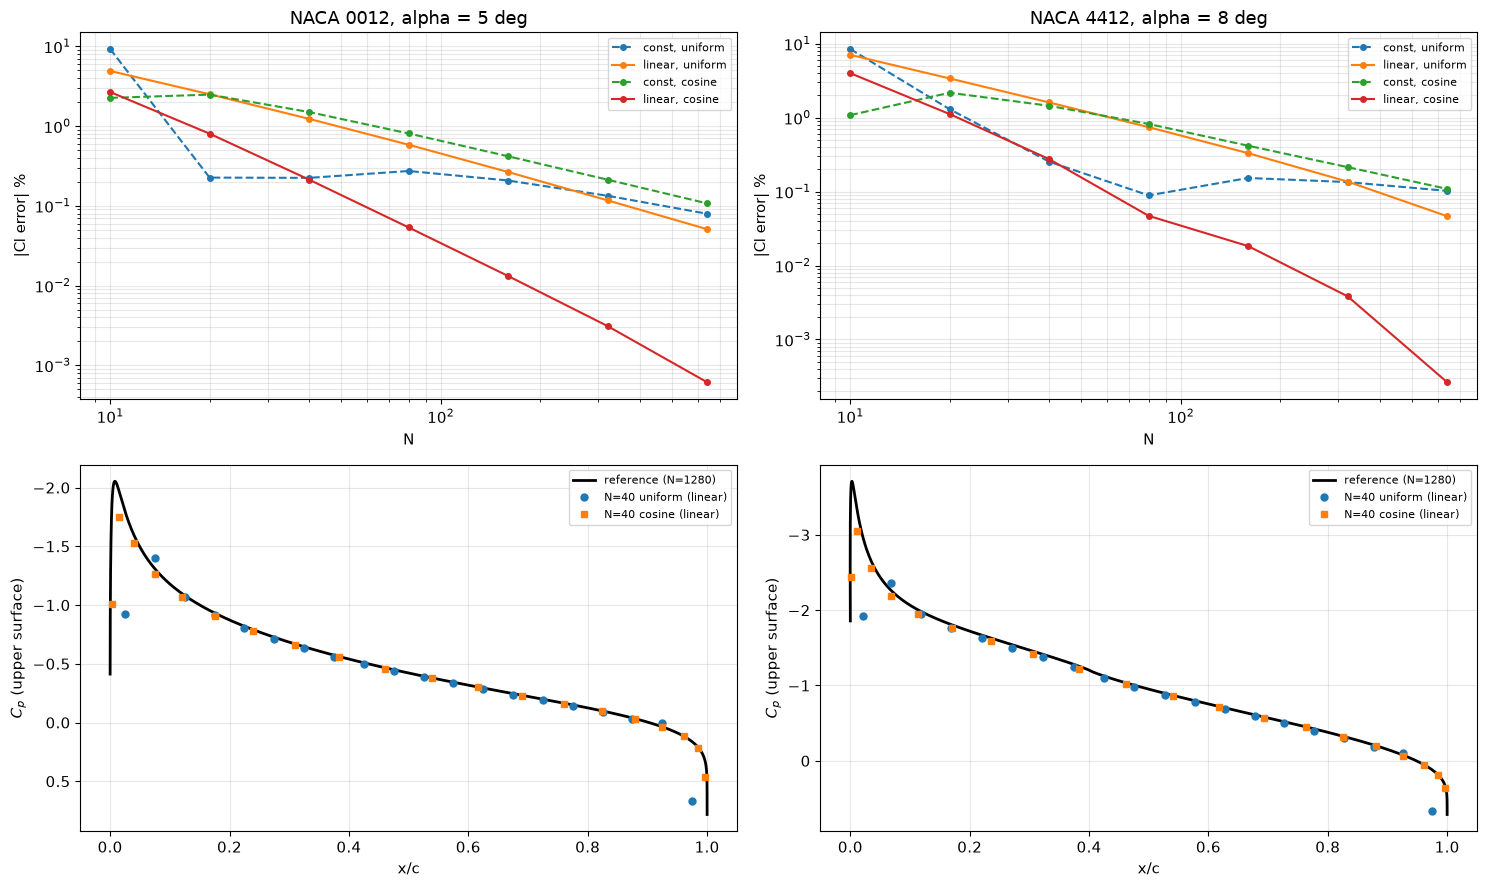

In [15]:
spacings = ["uniform", "cosine"]
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
for col, code_ in enumerate(["0012", "4412"]):
    R = ref[code_]
    for sp in spacings:
        for mname, f, ls in [("const", vortex_panel_method_0, "--"), ("linear", vortex_panel_method_1, "-")]:
            err = []
            for N in Ns_a:
                r = f(*naca4_geometry(code_, N, sp), ALPHA[code_])
                err.append(max(abs(r["Cl"] - R["Cl"])/R["Cl"]*100, 1e-5))
            ax[0, col].loglog(Ns_a, err, ls, marker="o", ms=4, label=f"{mname}, {sp}")
    ax[0, col].set_title(f"NACA {code_}, alpha = {ALPHA[code_]:.0f} deg"); ax[0, col].set_xlabel("N"); ax[0, col].set_ylabel("|Cl error| %")
    ax[0, col].grid(True, which="both"); ax[0, col].legend(fontsize=8)

    hR = len(R["xc"])//2
    ax[1, col].plot(R["xc"][hR:], R["Cp"][hR:], "k-", lw=2, label="reference (N=1280)")
    for sp, mk in zip(spacings, ["o", "s"]):
        r = vortex_panel_method_1(*naca4_geometry(code_, 40, sp), ALPHA[code_])
        ax[1, col].plot(r["xc"][20:], r["Cp"][20:], mk, ms=5, label=f"N=40 {sp} (linear)")
    ax[1, col].invert_yaxis(); ax[1, col].set_xlabel("x/c"); ax[1, col].set_ylabel("$C_p$ (upper surface)"); ax[1, col].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4.3 Result discussion for airfoil
- **Lift vs. number of panels:** The linear method converges faster than the constant method. For NACA 0012 its lift error is $0.21\%$, $0.054\%$ and $0.013\%$ at $N=40$, $80$ and $160$, falling roughly like $N^{-2}$. The constant method gives $1.5\%$, $0.81\%$ and $0.42\%$, which is first-order convergence. Both methods are within about $1.5\%$ of the reference at $N=40$.
- **Pressure vs. number of panels:** Away from the leading edge, the pressure distribution is already close to the reference for $N\gtrsim 40$. The suction peak at the leading edge is the hardest part to capture: for the linear method, $C_{p,\min}$ is about $15\%$ too low at $N=40$ and $3.6\%$ too low at $N=160$ (NACA 0012). A good leading-edge resolution is therefore the main requirement for accurate pressures.
- **Panel distribution:** For the linear method, cosine spacing is much better than uniform spacing. At $N=160$, the lift error is $0.013\%$ (0012) and $0.018\%$ (4412) with cosine spacing, against $0.27\%$ and $0.33\%$ with uniform spacing, and uniform spacing also resolves the suction peak worse. For the constant method, the lift errors with uniform spacing are small but do not decrease steadily with $N$, so no clear conclusion about spacing can be drawn from the lift alone.
- **Sanity check:** Both methods give $C_l\approx0$ for the symmetric NACA 0012 at $\alpha=0$ and a positive $C_l$ for the cambered NACA 4412, as expected.

## 5. Prediction of airfoil characteristics
Both functions are used with $N=160$ cosine-spaced panels to predict, NACA 0012 and NACA 4412, the lift curve $C_l (\alpha)$, the lift-curve slope and the pressure-coefficient distributions. The lift-curve slope is compared with the thin-airfoil value $2 \pi$ per radian and the thickness-corrected value of $2 \pi (1+0.77t/c)$.

In [16]:
N = 160
alphas = np.arange(-8.0, 13.0, 2.0)
airfoils = ["0012", "4412"]

data = {}
for code_ in airfoils:
    xb, yb = naca4_geometry(code_, N)
    for key, f in [("m0", vortex_panel_method_0), ("m1", vortex_panel_method_1)]:
        data[(code_, key)] = np.array([f(xb, yb, a)["Cl"] for a in alphas])

print(f"{'airfoil':8s}{'method':8s}{'Cl_alpha (/rad)':>17s}{'Cl (alpha=0)':>14s}")
for code_ in airfoils:
    for key in ("m0", "m1"):
        Cl = data[(code_, key)]
        slope = np.polyfit(np.radians(alphas), Cl, 1)[0]
        print(f"{code_:8s}{key:8s}{slope:17.3f}{np.interp(0.0, alphas, Cl):14.4f}")
print(f"\nthin-airfoil theory: Cl_alpha = 2*pi = {2*np.pi:.3f} /rad;", f"thickness-corrected 2*pi*(1 + 0.77 t/c) = {2*np.pi*(1+0.77*0.12):.3f} /rad for t/c = 12 %")

airfoil method    Cl_alpha (/rad)  Cl (alpha=0)
0012    m0                  6.918       -0.0000
0012    m1                  6.889       -0.0000
4412    m0                  6.900        0.5203
4412    m1                  6.870        0.5180

thin-airfoil theory: Cl_alpha = 2*pi = 6.283 /rad; thickness-corrected 2*pi*(1 + 0.77 t/c) = 6.864 /rad for t/c = 12 %


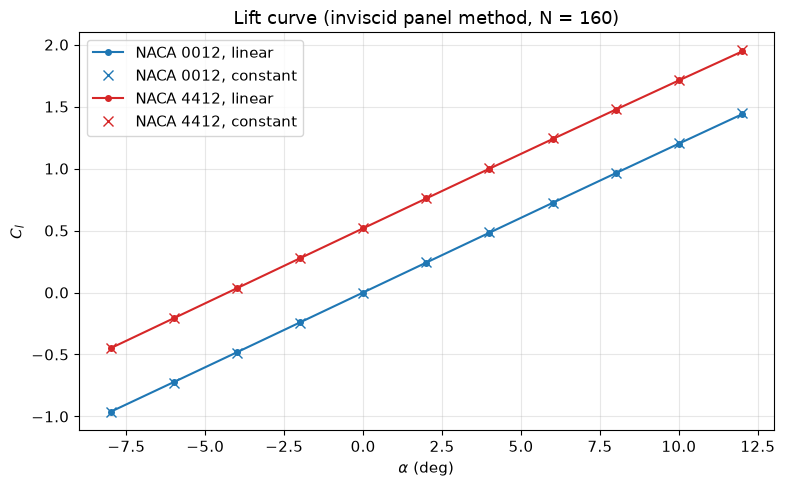

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
for code_, col in zip(airfoils, ["tab:blue", "tab:red"]):
    ax.plot(alphas, data[(code_, "m1")], "-o", color=col, ms=4, label=f"NACA {code_}, linear")
    ax.plot(alphas, data[(code_, "m0")], "x", color=col, ms=7, label=f"NACA {code_}, constant")
ax.set_xlabel(r"$\alpha$ (deg)"); ax.set_ylabel("$C_l$"); ax.set_title("Lift curve (inviscid panel method, N = 160)"); ax.legend()
plt.tight_layout(); plt.show()

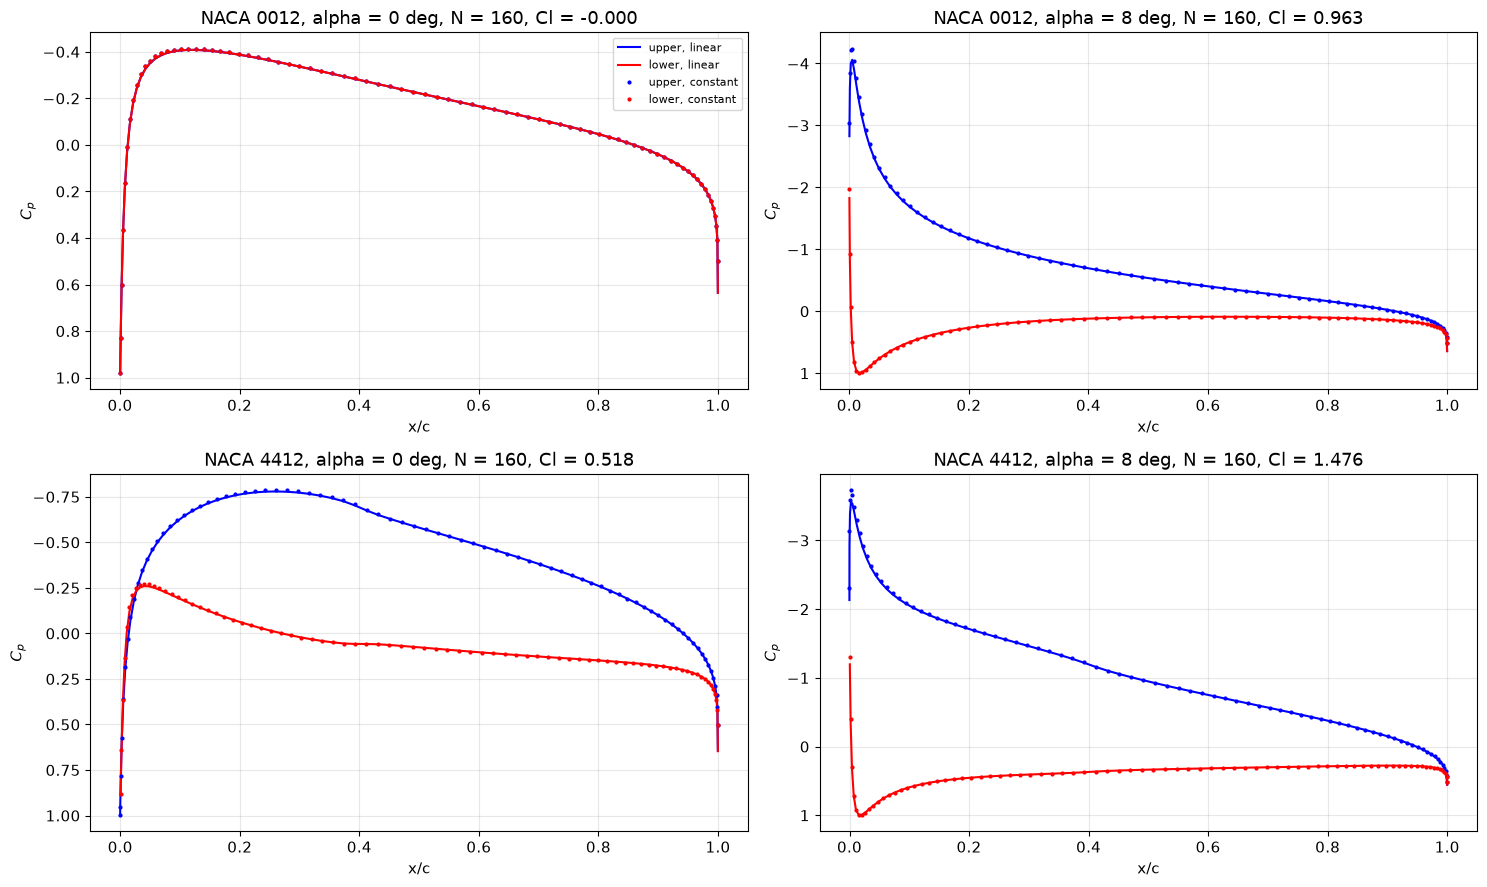

NACA 4412, 8 deg: Cp_min (upper) = -3.566  at x/c = 0.0025   Cl = 1.4757


In [19]:
# Pressure coefficient distributions with N = 160 for both methods
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
for row, code_ in enumerate(airfoils):
    xb, yb = naca4_geometry(code_, N)
    h = N//2                  
    for col, a in enumerate([0.0, 8.0]):
        r1 = vortex_panel_method_1(xb, yb, a); r0 = vortex_panel_method_0(xb, yb, a)
        A_ = ax[row, col]
        A_.plot(r1["xc"][h:], r1["Cp"][h:], "b-",  label="upper, linear")
        A_.plot(r1["xc"][:h], r1["Cp"][:h], "r-",  label="lower, linear")
        A_.plot(r0["xc"][h:], r0["Cp"][h:], "b.", ms=4, label="upper, constant")
        A_.plot(r0["xc"][:h], r0["Cp"][:h], "r.", ms=4, label="lower, constant")
        A_.invert_yaxis()
        A_.set_title(f"NACA {code_}, alpha = {a:.0f} deg, N = {N}, Cl = {r1['Cl']:.3f}")
        A_.set_xlabel("x/c"); A_.set_ylabel("$C_p$")
        if row == 0 and col == 0: A_.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Closer look at the leading-edge suction peak of NACA 4412 at 8 deg
xb, yb = naca4_geometry("4412", N); h = N//2
r1 = vortex_panel_method_1(xb, yb, 8.0)
print("NACA 4412, 8 deg: Cp_min (upper) =", round(r1["Cp"][h:].min(), 3),
      " at x/c =", round(r1["xc"][h:][np.argmin(r1["Cp"][h:])], 4), "  Cl =", round(r1["Cl"], 4))

## 5.1 Result discussion for airfoil characteristics
- **Lift curve:** \
   For both airfoils, the predicted $C_l(\alpha)$ is linear. The lift-curve slope (6.89 per radian with the linear method and 6.92 with the constant method for NACA 0012) is larger than the thin-airfoil value $2\pi=6.28$ because the panel method includes thickness effects; for $t/c=12\%$ the empirical correction $2\pi(1+0.77\,t/c)=6.86$ is reproduced within about 0.5 %. The NACA 0012 curve passes through the origin, while camber shifts the NACA 4412 curve upward ($C_l\approx0.52$ at $\alpha=0$). The constant and linear methods agree closely at $N=160$.
- **Pressure distributions:** \
   At $\alpha=0$, the NACA 0012 gives identical upper- and lower-surface curves, and the cambered section shows a suction side with lower pressure than the pressure side already at $\alpha=0$. At $\alpha=8^\circ$, a strong suction peak forms near the leading edge ($C_{p,\min}\approx-3.6$ for the 4412). The area between the upper and lower curves is the lift predicted by the method, and the two methods give the curves at $N=160$.

## 6. Limitations of prediction
A panel method solves **inviscid** flow. Real airfoils have boundary layers whose displacement and separation reduce lift and produce drag; these effects become important as the airfoil gets thicker, since thick sections have stronger adverse pressure gradients on the rear part of the upper surface.

Here the NACA 00$tt$ family ($tt=6$ to $24$ %) is analysed with the two functions at $N=320$. The numerical error is first shown to be independent of the thickness, so that any loss of predictive quality is due to the model and not to the discretisation. Two indicators are then compared with trends known from experiments (_Abbott & von Doenhoff, 1959_):
1. **Lift-curve slope** against thin-airfoil theory: the inviscid panel solution increases the slope with thickness ($\approx2\pi(1+0.77\,t/c)$), whereas measured slopes do not grow and tend to fall because the boundary layer thickens.
2. **Pressure distribution** on the upper surface: a deeper suction peak and a longer pressure recovery towards the trailing edge as $t/c$ grows. The rear part of the upper surface is where a real boundary layer is driven towards separation, a mechanism the panel method cannot represent.

In [20]:
thickness = [6, 9, 12, 15, 18, 21, 24]
N = 320; h = N//2
tab = []
curves = {}
for t in thickness:
    code_ = f"00{t:02d}"
    xb, yb = naca4_geometry(code_, N)
    r2, rm2 = vortex_panel_method_1(xb, yb, 2.0), vortex_panel_method_1(xb, yb, -2.0)
    slope1 = (r2["Cl"] - rm2["Cl"])/np.radians(4.0)
    slope0 = (vortex_panel_method_0(xb, yb, 2.0)["Cl"] - vortex_panel_method_0(xb, yb, -2.0)["Cl"])/np.radians(4.0)
    r = vortex_panel_method_1(xb, yb, 0.0)
    curves[t] = (r["xc"][h:], r["Cp"][h:])
    # numerical sensitivity at coarse N for the same airfoil
    ref_cl = vortex_panel_method_1(*naca4_geometry(code_, 640), 5.0)["Cl"]
    err40 = abs(vortex_panel_method_1(*naca4_geometry(code_, 40), 5.0)["Cl"] - ref_cl)/ref_cl*100
    tab.append((t, slope1, slope0, 2*np.pi*(1 + 0.77*t/100), r["Cp"][h:].min(), err40))

print(f"{'t/c %':>6s}{'Cla m1':>9s}{'Cla m0':>9s}{'2pi(1+.77t/c)':>15s}{'Cp_min (a=0)':>14s}{'Cl err N=40 %':>15s}")
for row in tab:
    print(f"{row[0]:6d}{row[1]:9.3f}{row[2]:9.3f}{row[3]:15.3f}{row[4]:14.3f}{row[5]:15.3f}")

 t/c %   Cla m1   Cla m0  2pi(1+.77t/c)  Cp_min (a=0)  Cl err N=40 %
     6    6.598    6.613          6.573        -0.207          0.212
     9    6.757    6.772          6.719        -0.308          0.214
    12    6.917    6.932          6.864        -0.411          0.212
    15    7.078    7.093          7.009        -0.516          0.210
    18    7.239    7.255          7.154        -0.623          0.207
    21    7.401    7.417          7.299        -0.731          0.204
    24    7.564    7.581          7.444        -0.843          0.202


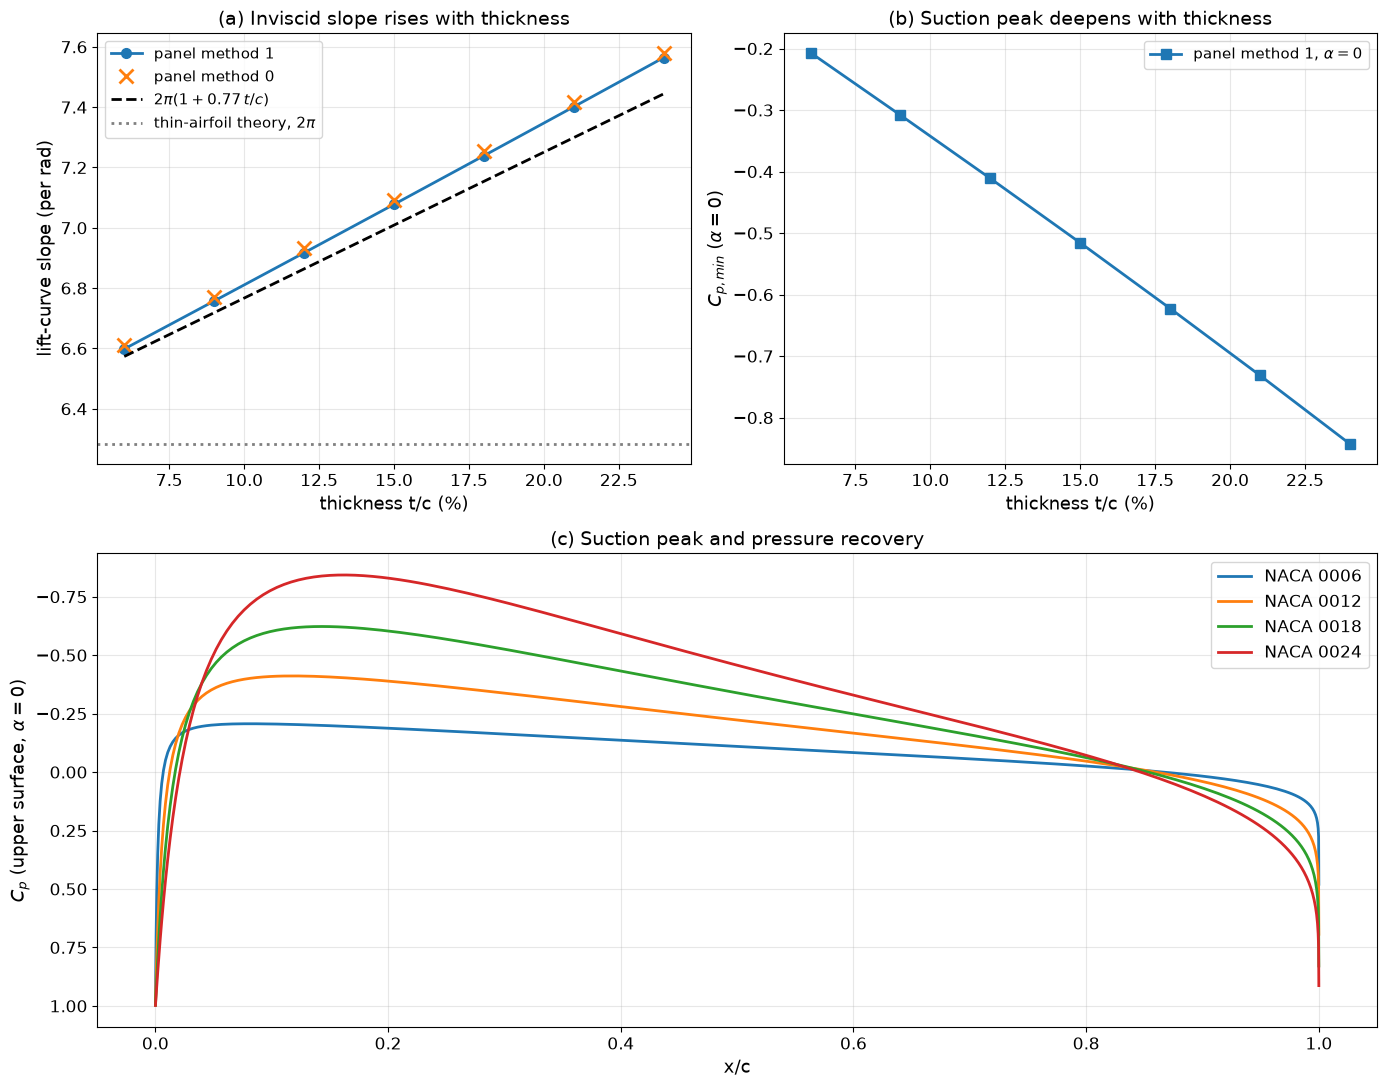

In [22]:
T = np.array([row[0] for row in tab])

fig = plt.figure(figsize=(14, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1])
ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[0, 1])
ax2 = fig.add_subplot(gs[1, :])        # spans the full width

# (a) lift-curve slope against thickness
ax0.plot(T, [r_[1] for r_ in tab], "o-", ms=7, lw=2, label="panel method 1")
ax0.plot(T, [r_[2] for r_ in tab], "x", ms=10, mew=2, label="panel method 0")
ax0.plot(T, [r_[3] for r_ in tab], "k--", lw=2, label=r"$2\pi(1+0.77\,t/c)$")
ax0.axhline(2*np.pi, color="gray", ls=":", lw=2, label=r"thin-airfoil theory, $2\pi$")
ax0.set_xlabel("thickness t/c (%)", fontsize=13); ax0.set_ylabel("lift-curve slope (per rad)", fontsize=13)
ax0.set_title("(a) Inviscid slope rises with thickness", fontsize=14); ax0.legend(fontsize=11)

# (b) minimum Cp against thickness
ax1.plot(T, [r_[4] for r_ in tab], "s-", ms=7, lw=2, label=r"panel method 1, $\alpha = 0$")   # <- label added
ax1.set_xlabel("thickness t/c (%)", fontsize=13); ax1.set_ylabel(r"$C_{p,min}$ ($\alpha = 0$)", fontsize=13)
ax1.set_title("(b) Suction peak deepens with thickness", fontsize=14)
ax1.legend(fontsize=11)                                                                        # <- legend added

# (c) upper-surface Cp distributions
for t in (6, 12, 18, 24):
    ax2.plot(*curves[t], lw=2, label=f"NACA 00{t:02d}")
ax2.invert_yaxis()
ax2.set_xlabel("x/c", fontsize=13); ax2.set_ylabel(r"$C_p$ (upper surface, $\alpha = 0$)", fontsize=13)
ax2.set_title("(c) Suction peak and pressure recovery", fontsize=14); ax2.legend(fontsize=12)

for a in (ax0, ax1, ax2):
    a.tick_params(labelsize=12)
plt.tight_layout(); plt.show()

## 6.1 Result Discussion for the limitations of panel methods:
- **Numerical error is independent of thickness:** The lift error at $N=40$ is practically the same for all sections from 6 % to 24 % (last column of the table). The code converges equally well for every thickness, so the loss of predictive ability described below is a limitation of the inviscid model and not a discretisation problem.
- **Lift-curve slope (plot a):** The predicted slope $C_{l\alpha}$ increases from about 6.6 to 7.6 per radian as the thickness grows from 6 % to 24 %, following $2\pi(1+0.77\,t/c)$ closely. This is the correct potential-flow result, but real flows behave differently: the slope stays roughly constant or decreases with thickness, because the boundary layer reduces the effective camber and thickness of the section. The over-prediction of lift therefore grows with $t/c$.
- **Pressure distribution (plots b and c):** At $\alpha=0$, a thicker airfoil has a deeper suction peak ($C_{p,\min}$ from about $-0.2$ to $-0.8$), and the pressure recovery along the rear of the upper surface extends over a larger part of the chord. In a viscous flow, this adverse pressure gradient promotes boundary-layer separation and early stall, causing a loss of lift and a large pressure drag. The panel method cannot represent this: it keeps predicting a lift curve that rises linearly with $\alpha$ (comparing _Liu_, _Fig. 1_, where the inviscid $C_l$ continues to rise beyond about $15^\circ$ while the experimental curve falls).

Thus, the panel method is reliable for thin or moderately thick airfoils at small angles of attack, where the flow stays attached. Its predictions become less reliable as thickness and angle of attack increase, and viscous corrections (boundary-layer coupling, as in Xfoil) are then needed.

# 7. References and acknowledgements

**Books and papers:**
1. H. Liu, "Linear Strength Vortex Panel Method for NACA 4412 Airfoil," *IOP Conf. Ser.: Mater. Sci. Eng.*, vol. 326, 012016, 2018. doi:10.1088/1757-899X/326/1/012016. (Formulation of the linear-strength method and geometry equations; Fig. 1 and Fig. 3 used for comparison.)
2. J. Katz and A. Plotkin, *Low-Speed Aerodynamics*, 2nd ed., Cambridge University Press, 2001. (Panel methods and the Kutta condition.)
3. A. M. Kuethe and C.-Y. Chow, *Foundations of Aerodynamics: Bases of Aerodynamic Design*, 5th ed., Wiley, 1998. (Vortex panel method with linear strength.)
4. J. D. Anderson, *Fundamentals of Aerodynamics*, McGraw-Hill, [edition, year]. (Thin-airfoil theory and cylinder flow.)
5. I. H. Abbott and A. E. von Doenhoff, *Theory of Wing Sections*, Dover, 1959. (NACA 4-digit geometry and experimental trends with thickness.)

**Course material and web resources:**

6. Course notes of AE 611, 2026.
7. Ansys Innovation Space, "Panel Methods & Vortex Lattice Method – Lesson 5," https://innovationspace.ansys.com/courses/courses/computational-aerodynamics-fundamentals/lessons/panel-method-and-vortex-lattice-method-lesson-5/ (accessed [date]).

**Acknowledgement of AI use:** AI assistance (Claude, ChatGPT, Google AI mode) was used to help restructure this notebook and to write and debug the vectorised implementation of the influence coefficients and the two solver functions. The formulation was checked against Liu (2018) and the exact cylinder solution, and the influence coefficients were verified against direct numerical quadrature. I have reviewed the code and the results, and I am responsible for the content of this report.

**Discussions:** I had regular discussions with classmates, in and outside class hours, on how to plot the panels for each case, how to plot the airfoils, and how the panel vectors change from one airfoil to another.